# TP 5

In [3]:
# Installation (décommente si besoin, une seule fois)
# %pip install -q scikit-learn pandas numpy matplotlib scipy emoji spacy nltk datasets
# !python -m spacy download en_core_web_sm

In [4]:
import warnings, re, html, unicodedata, time, random, os, sys, subprocess
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.base import clone
from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     cross_val_score, cross_val_predict, GridSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, precision_recall_curve, fbeta_score)

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED); random.seed(SEED)
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 200)
plt.rcParams["figure.dpi"] = 100

# Labels en ASCII pour garder un ordre alphabétique stable : negatif < neutre < positif
LABELS = ["negatif", "neutre", "positif"]

## 1. Collecte et chargement du jeu de données

Choix du jeu : **tweet_eval / sentiment** (Hugging Face, `cardiffnlp/tweet_eval`) : tweets réels en anglais, 3 classes (négatif, neutre, positif), plus de 50 000 textes. Comme le jeu dépasse 30 000 lignes, on extrait un **échantillon stratifié de 20 000 lignes**.

Plan B si Hugging Face est inaccessible : le CSV Kaggle *Twitter US Airline Sentiment* (`Tweets.csv`, 14 640 tweets, 3 classes) placé à côté du notebook.

In [5]:
def charger_donnees():
    # Option A : Hugging Face
    try:
        from datasets import load_dataset
        try:
            ds = load_dataset("cardiffnlp/tweet_eval", "sentiment")
        except Exception:
            ds = load_dataset("tweet_eval", "sentiment")
        d = pd.concat([ds[s].to_pandas() for s in ds.keys()], ignore_index=True)
        d = d.rename(columns={"text": "texte"})
        d["label"] = d["label"].map({0: "negatif", 1: "neutre", 2: "positif"})
        return d[["texte", "label"]], "tweet_eval / sentiment (Hugging Face)"
    except Exception as e:
        print("Hugging Face indisponible :", repr(e)[:160])
    # Option B : Kaggle Twitter US Airline Sentiment
    for p in ["Tweets.csv", "/content/Tweets.csv", "data/Tweets.csv"]:
        if os.path.exists(p):
            d = pd.read_csv(p).rename(columns={"text": "texte", "airline_sentiment": "label"})
            d["label"] = d["label"].map({"negative": "negatif", "neutral": "neutre", "positive": "positif"})
            return d[["texte", "label"]], "Twitter US Airline Sentiment (Kaggle)"
    raise FileNotFoundError("Ni Hugging Face ni Tweets.csv : télécharge l'un des deux jeux.")

df_all, SOURCE = charger_donnees()
print("Source :", SOURCE, "| lignes brutes :", len(df_all))

if len(df_all) > 30000:
    df_raw, _ = train_test_split(df_all, train_size=20000, stratify=df_all["label"], random_state=SEED)
else:
    df_raw = df_all
df_raw = df_raw[["texte", "label"]].reset_index(drop=True)   # df_raw restera INCHANGÉ
df_raw.head()

Generating validation split: 100%|██████████| 2000/2000 [00:00<00:00, 73901.28 examples/s]


Source : tweet_eval / sentiment (Hugging Face) | lignes brutes : 59899


,texte,label
0,Most stores requesting new Sunday liquor sale permits in Prince George's County are near the D.C. border,neutre
1,@user You played a Janet Jackson joint around 2am on Thursday NIght/Friday morning. No verses. Almost just...,positif
2,someone go to Disneyland with me starting the 11th I love Halloween time,positif
3,@user Ironman Wales in September? Fancy it? Warm welcome from us Welshies in Tenby!,positif
4,Fuck the EU out of existance #Brexit #Italexit,negatif


In [6]:
# Q1 : dimensions, classes, effectifs
print("Dimensions de df_raw :", df_raw.shape)
eff = df_raw["label"].value_counts().reindex(LABELS)
print(pd.DataFrame({"effectif": eff, "pourcentage": (100 * eff / eff.sum()).round(2)}))

# Q2 : valeurs manquantes, textes vides, doublons, retweets
n_na = int(df_raw["texte"].isna().sum() + df_raw["label"].isna().sum())
n_vide = int((df_raw["texte"].fillna("").str.strip() == "").sum())
n_dup = int(df_raw.duplicated(subset="texte").sum())
n_rt = int(df_raw["texte"].str.match(r"^\s*RT\b").sum())
print(f"\nValeurs manquantes : {n_na} | textes vides : {n_vide} | doublons exacts (texte) : {n_dup} | retweets (RT) : {n_rt}")
print("\nDoublons exacts par classe :")
print(df_raw[df_raw.duplicated(subset="texte", keep=False)]["label"].value_counts())

Dimensions de df_raw : (20000, 2)
         effectif  pourcentage
label                         
negatif      3799        19.00
neutre       9175        45.88
positif      7026        35.13

Valeurs manquantes : 0 | textes vides : 0 | doublons exacts (texte) : 2 | retweets (RT) : 72

Doublons exacts par classe :
label
neutre     2
positif    2
Name: count, dtype: int64


**Réponses (Section 1)**

1. Les dimensions, les classes et leurs effectifs sont affichés ci-dessus. Pour `tweet_eval`, la classe **neutre** est la plus fréquente, puis **positif**, et **négatif** est la plus rare : le jeu est déséquilibré.
2. Valeurs manquantes et textes vides : en général aucun. Les **doublons exacts** viennent surtout des retweets, des tweets automatiques ou de spam (même texte posté plusieurs fois) et de tweets très courts et génériques. Dans `tweet_eval`, les mentions sont déjà anonymisées en `@user` et les liens en `http`, ce qui explique aussi quelques doublons.

**Question de réflexion : décalage de domaine (*domain shift*)**
Un modèle entraîné sur des tweets ne généralise pas forcément à des avis de restaurants. Le décalage de domaine, c'est quand la distribution des données d'entraînement (vocabulaire, style, sujets, longueur, façon d'exprimer un avis) diffère de celle des données d'usage. Un mot comme « cold » est négatif pour un plat, neutre pour la météo. Conséquences sur l'interprétation : les scores mesurés sont valables pour **le domaine du test** (tweets), pas pour les restaurants, et la performance réelle sur un autre domaine sera probablement plus basse. Il faut donc évaluer sur des données du domaine cible ou faire de l'adaptation de domaine.

## 2. Exploration et analyse initiale

,effectif,%
label,,
negatif,3799,19.00
neutre,9175,45.88
positif,7026,35.13


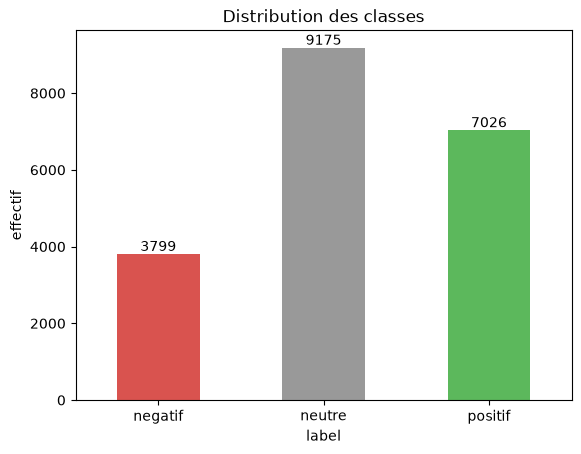

Taux d'équilibre (min/max) : 0.41
Accuracy d'un classifieur qui prédit toujours 'neutre' : 0.459


In [7]:
# (a) Distribution des classes
dist = df_raw["label"].value_counts().reindex(LABELS)
tab = pd.DataFrame({"effectif": dist, "%": (100 * dist / dist.sum()).round(2)})
display(tab)
ax = dist.plot(kind="bar", color=["#d9534f", "#999999", "#5cb85c"], rot=0)
ax.set_title("Distribution des classes"); ax.set_ylabel("effectif")
for i, v in enumerate(dist.values): ax.text(i, v, str(v), ha="center", va="bottom")
plt.show()

taux_equilibre = dist.min() / dist.max()
acc_majoritaire = dist.max() / dist.sum()
print(f"Taux d'équilibre (min/max) : {taux_equilibre:.2f}")
print(f"Accuracy d'un classifieur qui prédit toujours '{dist.idxmax()}' : {acc_majoritaire:.3f}")

label         negatif  neutre  positif
n_car  count   3799.0  9175.0   7026.0
       mean     108.3   101.8    103.2
       std       26.4    28.2     27.5
       min        9.0     9.0      6.0
       25%       92.0    82.0     84.0
       50%      114.0   108.0    108.0
       75%      129.0   123.0    125.0
       max      175.0   187.0    180.0
n_mots count   3799.0  9175.0   7026.0
       mean      19.1    17.8     18.5
       std        5.1     5.4      5.3
       min        2.0     1.0      1.0
       25%       16.0    14.0     15.0
       50%       20.0    18.0     19.0
       75%       23.0    22.0     22.0
       max       32.0    33.0     34.0

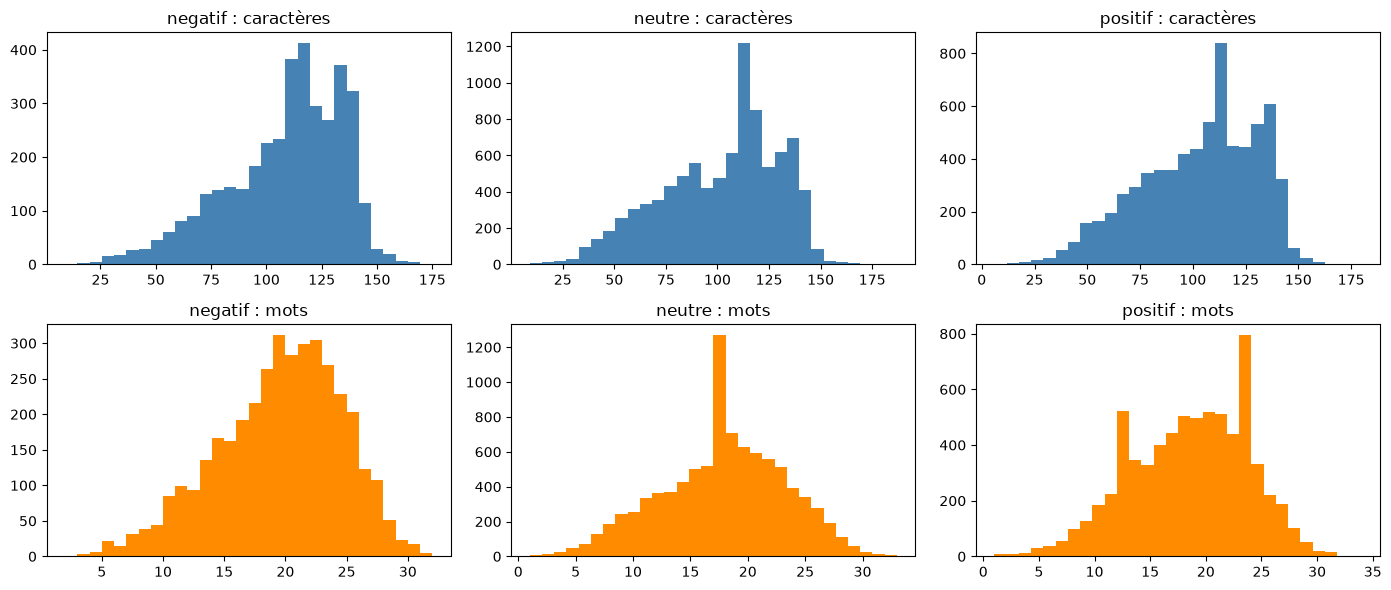

In [8]:
# (b) Longueur des textes par classe
tmp = df_raw.copy()
tmp["n_car"] = tmp["texte"].str.len()
tmp["n_mots"] = tmp["texte"].str.split().str.len()
display(tmp.groupby("label")[["n_car", "n_mots"]].describe().T.round(1))

fig, axes = plt.subplots(2, 3, figsize=(14, 6))
for j, lab in enumerate(LABELS):
    axes[0, j].hist(tmp.loc[tmp.label == lab, "n_car"], bins=30, color="steelblue")
    axes[0, j].set_title(f"{lab} : caractères")
    axes[1, j].hist(tmp.loc[tmp.label == lab, "n_mots"], bins=30, color="darkorange")
    axes[1, j].set_title(f"{lab} : mots")
plt.tight_layout(); plt.show()

In [9]:
# (c) Trois exemples par classe
for lab in LABELS:
    print(f"--- {lab} ---")
    for t in df_raw[df_raw.label == lab]["texte"].sample(3, random_state=SEED):
        print("  *", t)

# (d) 15 mots les plus fréquents par classe (sans aucun traitement, juste split sur les espaces)
top = {}
for lab in LABELS:
    c = Counter(w for t in df_raw.loc[df_raw.label == lab, "texte"] for w in t.lower().split())
    top[lab] = [f"{w} ({n})" for w, n in c.most_common(15)]
display(pd.DataFrame(top))

--- negatif ---
  * "Because you know that no matter how shitty you feel on a Tuesday morning, Maite feels shittier."
  * trying to watch ahs at a bar and the sun is just hating me
  * "1st they're trying Kane &amp; now Derrick Rose. Yeah, OK. I call bullshit. Lie detector tests should be mandatory when it comes to rape charges."
--- neutre ---
  * "The Undertaker looks to avenge The Streak when he faces Brock Lesnar at SummerSlam, THIS SUNDAY at 7e/4p, Live on...
  * @user Make my little girls Christmas please! Can not get hold of a #hatchimals anywhere
  * @user hey Matt my buddy got me a ticket for this Sunday's game against the Vikings. Any chance you're going and we could meet?
--- positif ---
  * Westworld is consistent in its mind bosting
  * "Rainy day, got alot done tho. Registration tmrw morning! Rdy to eat din and watch Sons of Anarchy, can't wait for the new season! #stoked"
  * @user if you are enjoying Bloodborne you may enjoy Dark Souls too if you didn't already played i

,negatif,neutre,positif
0,the (2648),the (6874),the (5342)
1,@user (2006),@user (3770),to (3109)
2,to (1564),to (3698),@user (2770)
3,a (1195),in (2611),i (1990)
4,i (1025),on (2337),and (1936)
5,is (1009),a (2212),a (1910)
6,and (994),and (2198),in (1853)
7,of (992),of (2053),on (1816)
8,in (974),for (1749),of (1581)
9,on (722),i (1701),for (1538)


In [10]:
# (e) Quantification du bruit : % de textes contenant chaque phénomène, par classe
import emoji
EMOTICON_DETECT = r"(?::|;|=)-?[\)\(DPpoO/\|]|<3"
bruit = {
    "URL":                (r"https?://\S+|www\.\S+|\bhttps?\b", 0),
    "Mention (@)":        (r"@\w+", 0),
    "Hashtag":            (r"#\w+", 0),
    "Émoticône":          (EMOTICON_DETECT, 0),
    "MAJUSCULES (3+)":    (r"\b[A-Z]{3,}\b", 0),
    "Lettres répétées":   (r"([A-Za-z])\1{2,}", 0),
    "!/? répétés":        (r"[!?]{2,}", 0),
    "Négation":           (r"\b(?:not|no|never|cannot|nobody|nothing|neither|pas|jamais|rien|aucun)\b|n't|n’t", re.I),
}
res = {}
for nom, (pat, fl) in bruit.items():
    res[nom] = df_raw["texte"].str.contains(pat, flags=fl, regex=True).groupby(df_raw["label"]).mean().reindex(LABELS) * 100
res["Émoji Unicode"] = df_raw["texte"].map(lambda t: emoji.emoji_count(t) > 0).groupby(df_raw["label"]).mean().reindex(LABELS) * 100
display(pd.DataFrame(res).T.round(1))

label,negatif,neutre,positif
URL,0.7,1.1,0.3
Mention (@),35.3,30.3,31.5
Hashtag,17.5,24.6,23.6
Émoticône,3.0,2.4,6.5
MAJUSCULES (3+),22.1,22.1,21.7
Lettres répétées,1.8,1.0,2.5
!/? répétés,4.2,3.3,8.1
Négation,32.4,15.3,12.8
Émoji Unicode,1.5,1.0,1.5


**Réponses (Section 2)**

1. Les classes ne sont pas équilibrées (voir taux d'équilibre). Un classifieur qui prédit toujours la classe majoritaire obtient l'accuracy 0.459 (de l'etape 2.a)
2. Les longueurs diffèrent un peu selon les classes. Pour un modèle par comptage de mots, un texte long a plus de mots non nuls et des comptes plus élevés. Sans normalisation (TF-IDF avec `sublinear_tf` et normalisation L2), la longueur influence artificiellement les scores. La normalisation L2 limite ce biais.
3. Les mots les plus fréquents sont surtout des mots grammaticaux (the, to, a, I, ...) car la loi de Zipf fait que quelques mots très courants dominent tous les textes. Ils ressemblent beaucoup d'une classe à l'autre et distinguent donc très peu les classes : c'est ce qui motive TF-IDF et la suppression (prudente) de stop words.

**Question de réflexion : pourquoi « neutre » est la classe la plus difficile ?**
La classe neutre n'a pas de vocabulaire propre : elle est définie par l'**absence** de polarité, donc elle ressemble à la fois aux textes légèrement positifs et légèrement négatifs. Les frontières sont floues (même les annotateurs humains se contredisent). Prévision pour la matrice de confusion : la diagonale est la plus faible pour *neutre*, avec beaucoup de neutre prédit positif ou négatif, et inversement ; les confusions négatif ↔ positif directes sont les plus rares.

## 3. Nettoyage NLP avancé

Chaîne **modulaire** : chaque opération est une fonction indépendante, activée ou non par un dictionnaire de drapeaux. Les variantes V0 à V6 (utilisées pour l'étude d'ablation de la section 6) sont définies à la fin de cette section.

**Hypothèses formulées avant mesure (vérifiées en section 6)**

| Op. | Hypothèse sur l'effet sur le F1 |
|---|---|
| (i) structurel | gain faible mais sûr (retire du bruit technique, `&amp;`, balises) |
| (ii) URL / mentions / RT | gain faible : les jetons `URL`, `USER` généralisent mieux que des liens uniques |
| (iii) hashtags | gain faible à moyen : `#NotHappy` devient `not happy` |
| (iv) émojis → texte | gain moyen : l'émoji est souvent le seul indice de polarité |
| (v) contractions / argot | gain moyen : `don't` devient `do not`, donc la négation est visible |
| (vi) allongements / `!!!` | gain faible : indicateur d'intensité |
| (vii) MAJUSCULES | gain faible : indicateur d'emphase |
| (viii) négation (`NEG_`) | gain moyen : sépare `good` de `not good` |
| (ix) lemmatisation + stop words personnalisés | effet incertain : réduit la dimension mais peut perdre de l'information ; supprimer aussi les négations (V6) devrait **dégrader** |

In [11]:
import emoji
import spacy

SPECIAL = {"URL", "USER", "EXCL", "QUEST", "ELONG", "ALLCAPS"}

try:
    nlp = spacy.load("en_core_web_sm", disable=["parser", "ner"])
except OSError:
    subprocess.run([sys.executable, "-m", "spacy", "download", "en_core_web_sm"], check=True)
    nlp = spacy.load("en_core_web_sm", disable=["parser", "ner"])

# ---------- Ressources ----------
EMOTICONS = [   # l'ordre compte (cry avant sad)
    (r"(?::|=)-?\)+|\(-?:|:-?\]|\^_\^", " smile "),
    (r"(?::|=)-?D+\b|\bxD\b", " laugh "),
    (r";-?[\)D]", " wink "),
    (r":'-?\(|;_;", " cry "),
    (r"(?::|=)-?\(+|\)-?:", " sad "),
    (r":-?[pP]\b", " tongue "),
    (r"(?::|=)-?[/\\]|:-?\|", " skeptical "),
    (r"<3", " love "),
    (r":-?[oO]\b", " surprise "),
]
CONTRACTIONS = [
    (r"\bwon't\b", "will not"), (r"\bcan't\b", "cannot"), (r"\bshan't\b", "shall not"), (r"\bain't\b", "is not"),
    (r"n't\b", " not"), (r"'re\b", " are"), (r"'m\b", " am"), (r"'ll\b", " will"),
    (r"'ve\b", " have"), (r"'d\b", " would"), (r"'s\b", ""),
]
SLANG = {"u": "you", "ur": "your", "gr8": "great", "thx": "thanks", "thnx": "thanks", "thanx": "thanks",
         "lol": "laughing", "lmao": "laughing", "omg": "oh my god", "idk": "i do not know",
         "btw": "by the way", "pls": "please", "plz": "please", "b4": "before", "2day": "today",
         "2morrow": "tomorrow", "tmrw": "tomorrow", "luv": "love", "wtf": "what the hell",
         "smh": "shaking my head", "imo": "in my opinion", "gonna": "going to", "wanna": "want to",
         "gotta": "got to", "cuz": "because", "coz": "because", "bc": "because", "ya": "you",
         "tho": "though", "rly": "really", "ppl": "people", "fyi": "for your information"}
NEGATIONS = {"not", "no", "never", "cannot", "nobody", "nothing", "neither", "nor", "nowhere", "none",
             "pas", "jamais", "rien", "aucun", "ni"}

STOP_ALL = set(nlp.Defaults.stop_words)
KEEP = {  # négations, intensifieurs, connecteurs d'opposition à CONSERVER
    "not", "no", "never", "nor", "none", "nobody", "nothing", "neither", "nowhere", "cannot", "n't",
    "very", "too", "really", "quite", "so", "much", "more", "most", "less", "just",
    "but", "however", "although", "though", "yet", "still", "without", "against",
    "pas", "jamais", "rien", "aucun", "ni", "très", "trop", "mais", "plus"}
STOP_CUSTOM = STOP_ALL - KEEP

# ---------- Opérations (une fonction par opération) ----------
def f_structural(t):                                    # (i)
    t = html.unescape(html.unescape(t))
    t = re.sub(r"</?[a-zA-Z][^>]*>", " ", t)
    t = unicodedata.normalize("NFKC", t)
    t = t.replace("’", "'").replace("‘", "'").replace("“", '"').replace("”", '"')
    return re.sub(r"\s+", " ", t).strip()

def f_url_mentions(t):                                  # (ii)
    t = re.sub(r"(?:^|\s)RT\s+(?=@\w+)", " ", t)
    t = re.sub(r"https?://\S+|www\.\S+|\bhttps?\b", " URL ", t)
    t = re.sub(r"@\w+", " USER ", t)
    return re.sub(r"\s+", " ", t).strip()

def _seg_hashtag(m):
    w = m.group(1).replace("_", " ")
    w = re.sub(r"(?<=[a-z0-9])(?=[A-Z])", " ", w)       # NotHappy -> Not Happy
    w = re.sub(r"(?<=[A-Z])(?=[A-Z][a-z])", " ", w)
    return " " + w + " "
def f_hashtags(t):                                      # (iii)
    return re.sub(r"#(\w+)", _seg_hashtag, t)

def f_emoji(t):                                         # (iv)
    for pat, rep in EMOTICONS:
        t = re.sub(pat, rep, t)
    t = emoji.demojize(t, delimiters=(" ", " "))
    return re.sub(r"\s+", " ", t).strip()

def f_contractions_slang(t):                            # (v)
    for pat, rep in CONTRACTIONS:
        t = re.sub(pat, rep, t, flags=re.I)
    t = re.sub(r"\b[\w']+\b", lambda m: SLANG.get(m.group(0).lower(), m.group(0)), t)
    return re.sub(r"\s+", " ", t).strip()

def _elong(m):
    return re.sub(r"([A-Za-z])\1{2,}", r"\1\1", m.group(0)) + " ELONG "
def f_elongation(t):                                    # (vi)
    t = re.sub(r"\b\w*([A-Za-z])\1{2,}\w*\b", _elong, t)
    t = re.sub(r"[!?]*(?:!\?|\?!)[!?]*", " EXCL QUEST ", t)
    t = re.sub(r"!{2,}", " EXCL ", t)
    t = re.sub(r"\?{2,}", " QUEST ", t)
    return re.sub(r"\s+", " ", t).strip()

def f_allcaps(t):                                       # (vii)
    def r(m):
        w = m.group(0)
        return w if w in SPECIAL else w.lower() + " ALLCAPS "
    return re.sub(r"\b[A-Z]{3,}\b", r, t)

def f_lower(t):                                         # (ix, partie minuscules)
    return re.sub(r"\w+", lambda m: m.group(0) if m.group(0) in SPECIAL else m.group(0).lower(), t)

def mark_negation(tokens, window=3):                    # (viii)
    out, n = [], 0
    for tok in tokens:
        if tok == "<P>" or not re.search(r"\w", tok):   # ponctuation = fin de portée
            n = 0; out.append(tok); continue
        if tok.lower() in NEGATIONS:
            n = window; out.append(tok); continue
        if n > 0 and tok not in SPECIAL:
            out.append("NEG_" + tok); n -= 1
        else:
            out.append(tok)
    return out

def clean_pre(t, f):
    if f.get("structural"):   t = f_structural(t)
    if f.get("url"):          t = f_url_mentions(t)
    if f.get("hashtag"):      t = f_hashtags(t)
    if f.get("emoji"):        t = f_emoji(t)
    if f.get("contractions"): t = f_contractions_slang(t)
    if f.get("elongation"):   t = f_elongation(t)
    if f.get("allcaps"):      t = f_allcaps(t)
    if f.get("lower"):        t = f_lower(t)
    return re.sub(r"\s+", " ", t).strip()

def spacy_tokens(texts, batch=512):                     # (ix) lemmatisation avec étiquetage POS
    out = []
    for doc in nlp.pipe(texts, batch_size=batch):
        toks = []
        for tk in doc:
            if tk.is_space: continue
            if tk.text in SPECIAL: toks.append((tk.text, tk.text, False)); continue
            if tk.is_punct or tk.pos_ in ("PUNCT", "SYM"): toks.append((tk.text, tk.text, True)); continue
            toks.append((tk.text.lower(), tk.lemma_.lower(), False))
        out.append(toks)
    return out

def finish_spacy(toks, stop):                           # stop words + négation + suppression ponctuation
    seq = []
    for text, lemma, is_p in toks:
        if is_p: seq.append("<P>"); continue
        if text in SPECIAL: seq.append(text); continue
        if stop == "custom" and text in STOP_CUSTOM: continue
        if stop == "all" and text in STOP_ALL: continue
        seq.append(lemma)
    seq = mark_negation(seq)
    return " ".join(t for t in seq if t != "<P>")

# Petit test
test = "OMG!!! I don't LOVE this soooo much :( #NotHappy http://x.co @bob"
p3 = clean_pre(test, dict(structural=1, url=1, hashtag=1, emoji=1, contractions=1, elongation=1, allcaps=1, lower=1))
print("V3 :", p3)
print("V4 :", " ".join(mark_negation(re.findall(r"\w+|[^\w\s]", p3))))
print("V5 :", finish_spacy(spacy_tokens([p3])[0], "custom"))

V3 : oh my god EXCL i do not love ALLCAPS this soo ELONG much sad not happy URL USER
V4 : oh my god EXCL i do not NEG_love ALLCAPS NEG_this NEG_soo ELONG much sad not NEG_happy URL USER
V5 : oh god EXCL not NEG_love ALLCAPS NEG_soo ELONG NEG_much sad not NEG_happy URL USER


In [12]:
# Définition des variantes de l'étude d'ablation
F0 = {}
F1 = dict(structural=1, url=1, lower=1)                                        # V1 : HTML, URL, minuscules
F2 = {**F1, "emoji": 1}                                                        # V2 : + émojis/émoticônes
F3 = {**F2, "hashtag": 1, "contractions": 1, "elongation": 1, "allcaps": 1}    # V3 : + contractions, argot, allongements (+ hashtags, MAJ)

def construire_variantes(df):
    d = df.copy()
    d["texte_v0"] = d["texte"]
    d["texte_v1"] = [clean_pre(t, F1) for t in d["texte"]]
    d["texte_v2"] = [clean_pre(t, F2) for t in d["texte"]]
    d["texte_v3"] = [clean_pre(t, F3) for t in d["texte"]]
    d["texte_v4"] = [" ".join(mark_negation(re.findall(r"\w+|[^\w\s]", s))) for s in d["texte_v3"]]
    toks = spacy_tokens(list(d["texte_v3"]))                     # lemmatisation calculée une seule fois
    d["texte_v5"] = [finish_spacy(x, "custom") for x in toks]    # stop words personnalisés (garde négations)
    d["texte_v6"] = [finish_spacy(x, "all") for x in toks]       # TOUS les stop words supprimés
    d["texte_brut"], d["texte_basique"], d["texte_avance"] = d["texte_v0"], d["texte_v1"], d["texte_v5"]
    return d

# Étape 0 : doublons exacts du texte brut (df_raw reste intact)
def effectifs(d): return d["label"].value_counts().reindex(LABELS).fillna(0).astype(int)
suivi = {"0. df_raw": effectifs(df_raw)}
df_work = df_raw.copy()
df_work = df_work[df_work["texte"].fillna("").str.strip() != ""]
df_work = df_work.drop_duplicates(subset="texte").reset_index(drop=True)
suivi["1. sans vides ni doublons exacts"] = effectifs(df_work)

t0 = time.time()
df_var = construire_variantes(df_work)
print(f"Nettoyage de {len(df_var)} textes en {time.time()-t0:.0f} s")

# Étape 2 : textes devenus très courts (< 3 mots) après nettoyage avancé
df_var = df_var[df_var["texte_avance"].str.split().str.len() >= 3]
suivi["2. >= 3 mots après nettoyage"] = effectifs(df_var)
# Étape 3 : doublons après nettoyage avancé
df_clean = df_var.drop_duplicates(subset="texte_avance").reset_index(drop=True)
suivi["3. sans doublons après nettoyage"] = effectifs(df_clean)

suivi = pd.DataFrame(suivi).T
suivi["total"] = suivi[LABELS].sum(axis=1)
display(suivi)
perte = (100 * (1 - suivi.iloc[-1][LABELS] / suivi.iloc[0][LABELS])).round(1)
print("Perte totale par classe (%) :", perte.to_dict())
print("Taille finale :", df_clean.shape)
df_clean[["texte_brut", "texte_basique", "texte_avance", "label"]].head(5)

Nettoyage de 19998 textes en 63 s


label,negatif,neutre,positif,total
0. df_raw,3799,9175,7026,20000
1. sans vides ni doublons exacts,3799,9174,7025,19998
2. >= 3 mots après nettoyage,3795,9146,7011,19952
3. sans doublons après nettoyage,3789,9139,7007,19935


Perte totale par classe (%) : {'negatif': 0.3, 'neutre': 0.4, 'positif': 0.3}
Taille finale : (19935, 12)


,texte_brut,texte_basique,texte_avance,label
0,Most stores requesting new Sunday liquor sale permits in Prince George's County are near the D.C. border,most stores requesting new sunday liquor sale permits in prince george's county are near the d.c. border,most store request new sunday liquor sale permit prince george county near d.c border,neutre
1,@user You played a Janet Jackson joint around 2am on Thursday NIght/Friday morning. No verses. Almost just...,USER you played a janet jackson joint around 2am on thursday night/friday morning. no verses. almost just ...,USER play janet jackson joint 2 thursday night friday morning no NEG_verse just instrumental loop,positif
2,someone go to Disneyland with me starting the 11th I love Halloween time,someone go to disneyland with me starting the 11th i love halloween time,disneyland start 11th love halloween time,positif
3,@user Ironman Wales in September? Fancy it? Warm welcome from us Welshies in Tenby!,USER ironman wales in september? fancy it? warm welcome from us welshies in tenby!,USER ironman wale september fancy warm welcome welshie tenby,positif
4,Fuck the EU out of existance #Brexit #Italexit,fuck the eu out of existance #brexit #italexit,fuck eu existance brexit italexit,negatif


In [13]:
# Q2 : cinq exemples avant / après
cats = {
    "émoji":        lambda t: emoji.emoji_count(t) > 0 or bool(re.search(EMOTICON_DETECT, t)),
    "négation":     lambda t: bool(re.search(r"\b(not|never|no)\b", t, re.I)),
    "contraction":  lambda t: bool(re.search(r"n't|'ll|'re|'ve", t, re.I)),
    "hashtag":      lambda t: bool(re.search(r"#[A-Z]\w*[a-z][A-Z]", t)) or "#" in t,
    "allongement":  lambda t: bool(re.search(r"([A-Za-z])\1{2,}", t)),
}
rows = []
for nom, fn in cats.items():
    sel = df_clean[df_clean["texte"].map(fn)]
    if len(sel):
        r = sel.sample(1, random_state=SEED).iloc[0]
        rows.append({"opération": nom, "avant": r["texte"], "après (avancé)": r["texte_avance"]})
display(pd.DataFrame(rows))

# Q3 : exemples où l'émoji est (presque) le seul indice
courts = df_clean[df_clean["texte"].map(lambda t: emoji.emoji_count(t) > 0 and len(re.sub(r"[^\w\s]", "", emoji.replace_emoji(t, "")).split()) <= 4)]
print("\nTextes courts dont l'émoji porte l'essentiel du sentiment :")
display(courts[["texte", "texte_v1", "texte_v2", "label"]].head(5))

# Q6 : lemmatisation vs racinisation
from nltk.stem import PorterStemmer
ps = PorterStemmer()
mots = ["better", "worse", "was", "studies", "feeling", "happily", "caring", "university", "universal"]
docs = nlp(" ".join(mots))
print("\nmot -> racinisation (Porter) | lemme (spaCy)")
for tk, m in zip(docs, mots):
    print(f"{m:11s} -> {ps.stem(m):10s} | {tk.lemma_}")

,opération,avant,après (avancé)
0,émoji,Tomorrow is the day we\u2019ll beat justin biebers vevo record and earn our title back! :) :),tomorrow day we\u2019ll beat justin biebers vevo record earn title smile smile
1,négation,"""You would think being the first Music Video without Zayn, it may not do so well, but in reality it's frea...",think music video without zayn not NEG_so but reality freak awesome drag music video
2,contraction,Salman you may be a celebrity but that doesn't mean you have the licence to say Yakub is innocent.Just sti...,salman celebrity but not NEG_mean NEG_licence NEG_yakub innocent.just stick act
3,hashtag,"""Rainy day, got alot done tho. Registration tmrw morning! Rdy to eat din and watch Sons of Anarchy, can't ...",rainy day get alot though registration tomorrow morning rdy eat din watch son anarchy not NEG_wait NEG_new...
4,allongement,looooooooove!!!!!!!!!!!! #onedirection,loove ELONG EXCL onedirection



Textes courts dont l'émoji porte l'essentiel du sentiment :


,texte,texte_v1,texte_v2,label
349,Good morning! ❤️ #ScreamQueens,good morning! ❤️ #screamqueens,good morning! red_heart #screamqueens,positif
2907,Louie 😍♥ #onedirection #MPN & #MtvStarsNiallHoran,louie 😍♥ #onedirection #mpn & #mtvstarsniallhoran,louie smiling_face_with_heart-eyes heart_suit #onedirection #mpn & #mtvstarsniallhoran,positif
4319,😇 (Vine by #TheWalkingDead),😇 (vine by #thewalkingdead),smiling_face_with_halo (vine by #thewalkingdead),positif
4343,#TheWalkingDead EM MEMORIA 😳🌸MERLET-DOGLORISOPHIAGLENNABRAHAMBOBJACQUILIZZIETYREESEGOVERNADORSAMBETHNOAHAN...,#thewalkingdead em memoria 😳🌸merlet-doglorisophiaglennabrahambobjacquilizzietyreesegovernadorsambethnoahan...,#thewalkingdead em memoria flushed_face cherry_blossom merlet-doglorisophiaglennabrahambobjacquilizzietyre...,positif
4650,#Repost @user with repostapp・・・#nationalfastfoodday 🍟,#repost USER with repostapp・・・#nationalfastfoodday 🍟,#repost USER with repostapp・・・#nationalfastfoodday french_fries,neutre



mot -> racinisation (Porter) | lemme (spaCy)
better      -> better     | well
worse       -> wors       | bad
was         -> wa         | be
studies     -> studi      | study
feeling     -> feel       | feel
happily     -> happili    | happily
caring      -> care       | care
university  -> univers    | university
universal   -> univers    | universal


**Réponses (Section 3)**

1. Le tableau de suivi ci-dessus donne, pour chaque étape, les lignes restantes **par classe**. Les suppressions touchent davantage les classes qui contiennent beaucoup de textes courts ou génériques (souvent *neutre*, avec des tweets très courts, ou des doublons de spam). Un déséquilibre dans les suppressions modifie légèrement les proportions de classes : il faut le signaler.
2. Les cinq exemples avant/après (émoji, négation, contraction, hashtag, allongement) sont affichés ci-dessus.
3. **Pourquoi convertir un émoji en texte plutôt que le supprimer ?** Parce qu'un émoji porte souvent le sentiment à lui seul. Exemple : « Quelle journée 😡 » ou « Thanks a lot 🙄 » : une fois l'émoji supprimé, le texte devient neutre ou même positif, donc la polarité est perdue. Converti en `angry_face` ou `rolling_eyes`, le sens est conservé dans le sac de mots.
4. **Portée de la négation** : après un mot de négation, les mots suivants (jusqu'à la prochaine ponctuation, au plus 3 mots) reçoivent le préfixe `NEG_`. Ainsi `not good` devient `not NEG_good`. Dans un sac de mots, l'ordre est perdu : sans marquage, `not good` et `good` partagent le mot `good`, tiré vers le positif, alors que le sens est inversé. Avec `NEG_good`, on obtient une dimension différente, que le modèle peut associer au négatif.
5. **Pourquoi garder `not`, `no`, `never` ?** Ce sont des mots qui **inversent la polarité**. Les supprimer transforme « not good » en « good » : le sens est inversé et le modèle apprend des associations fausses (baisse de rappel et de précision sur *négatif*). Ils figurent dans les listes de stop words standard (c'est pourquoi on construit une liste personnalisée). La comparaison V5 / V6 (section 6) le mesure.
6. **Lemmatisation vs racinisation** : la lemmatisation (avec POS) donne de vrais mots (`better` -> `well`, `was` -> `be`, `studies` -> `study`), alors que le stemming coupe brutalement et crée des collisions (`university` / `universal` -> `univers`) ou des non-mots, ce qui brouille le sens et les termes discriminants à interpréter.
7. **Limites** : un dictionnaire d'abréviations est limité (couverture partielle, ambiguïté : `ur`, `u`, `r`), dépend de la langue, de l'époque et de la communauté, et ne couvre pas l'argot nouveau. Un correcteur orthographique automatique « corrige » à tort les noms propres, l'argot, les mots de la darija, les hashtags, et efface des indices de sentiment (allongements, fautes volontaires).

**Question de réflexion** : un nettoyage « avancé » n'est pas toujours meilleur. Chaque opération est une hypothèse : elle peut apporter de l'information (émojis, négation) ou en détruire (suppression des négations, lemmatisation trop agressive). Le verdict vient de l'ablation (section 6).

## 4. Découpage et représentation vectorielle

### 4.1 Découpage 80 % / 20 % (stratifié)
Le jeu de test (`test_df`) est mis de côté et **ne sera utilisé qu'en section 7**.

In [14]:
train_df, test_df = train_test_split(df_clean, test_size=0.2, stratify=df_clean["label"], random_state=SEED)
train_df, test_df = train_df.reset_index(drop=True), test_df.reset_index(drop=True)
print("Train :", len(train_df), "| Test :", len(test_df))
display(pd.DataFrame({
    "train (%)": (100 * train_df["label"].value_counts(normalize=True)).reindex(LABELS).round(2),
    "test (%)":  (100 * test_df["label"].value_counts(normalize=True)).reindex(LABELS).round(2)}))
y_train = train_df["label"]

Train : 15948 | Test : 3987


,train (%),test (%)
label,,
negatif,19.01,19.01
neutre,45.84,45.85
positif,35.15,35.14


### 4.2 Vectorisation (dans un `Pipeline`, ajustée sur le train seulement)

In [15]:
def make_vec(kind, ngram=(1, 1)):
    if kind == "bow":
        return CountVectorizer(min_df=3, max_df=0.9, ngram_range=ngram)
    if kind == "tfidf_word":
        return TfidfVectorizer(min_df=3, max_df=0.9, sublinear_tf=True, ngram_range=ngram)
    if kind == "tfidf_char":
        return TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=3, max_df=0.9, sublinear_tf=True)
    raise ValueError(kind)

VEC_KINDS = ["bow", "tfidf_word", "tfidf_char"]
X_text_train = train_df["texte_avance"]       # nettoyage avancé (V5) par défaut ; la section 6 dira quelle variante garder

# un texte d'exemple par classe (pour voir les termes les plus pondérés)
exemples = [train_df[train_df.label == lab].iloc[0] for lab in LABELS]

rows = []
for kind in VEC_KINDS:
    vec_pipe = Pipeline([("vec", make_vec(kind))])
    Xtr = vec_pipe.fit_transform(X_text_train)           # fit sur TRAIN uniquement
    n_docs, n_feat = Xtr.shape
    sparsite = 1 - Xtr.nnz / (n_docs * n_feat)
    rows.append({"représentation": kind, "documents": n_docs, "dimensions": n_feat, "sparsité (%)": round(100 * sparsite, 2)})
    names = np.array(vec_pipe.named_steps["vec"].get_feature_names_out())
    print(f"\n=== {kind} : top termes pondérés ===")
    for lab, ex in zip(LABELS, exemples):
        row = vec_pipe.transform([ex["texte_avance"]])
        idx = np.argsort(row.toarray().ravel())[::-1][:5]
        print(f"  [{lab}] {ex['texte_avance'][:70]!r}\n      -> {[(names[i], round(row[0, i], 3)) for i in idx]}")
display(pd.DataFrame(rows))


=== bow : top termes pondérés ===
  [negatif] 'teen vogue call steve bannon sub human shit normalize'
      -> [('normalize', np.int64(1)), ('steve', np.int64(1)), ('sub', np.int64(1)), ('shit', np.int64(1)), ('teen', np.int64(1))]
  [neutre] 'USER usually mosque farmington hill but get exam tomorrow so not NEG_g'
      -> [('tomorrow', np.int64(1)), ('user', np.int64(1)), ('so', np.int64(1)), ('not', np.int64(1)), ('usually', np.int64(1))]
  [positif] 'happy sunday bee gee walk air'
      -> [('sunday', np.int64(1)), ('walk', np.int64(1)), ('happy', np.int64(1)), ('gee', np.int64(1)), ('bee', np.int64(1))]

=== tfidf_word : top termes pondérés ===
  [negatif] 'teen vogue call steve bannon sub human shit normalize'
      -> [('normalize', np.float64(0.454)), ('sub', np.float64(0.42)), ('teen', np.float64(0.345)), ('human', np.float64(0.339)), ('bannon', np.float64(0.332))]
  [neutre] 'USER usually mosque farmington hill but get exam tomorrow so not NEG_g'
      -> [('mosque', np.float

,représentation,documents,dimensions,sparsité (%)
0,bow,15948,7028,99.86
1,tfidf_word,15948,7028,99.86
2,tfidf_char,15948,46831,99.59


**Réponses (Section 4)**

1. Les tailles train/test et les proportions de classes sont affichées ci-dessus : grâce à `stratify`, les proportions sont conservées dans les deux ensembles.
2. Le vectoriseur doit être ajusté sur le train seulement : il apprend un **vocabulaire** et des **IDF** (fréquences de documents). Si on l'ajuste sur tout le jeu, les statistiques du test (mots rares ou fréquents du test) influencent l'espace de représentation : c'est une **fuite d'information** (*data leakage*) qui rend les scores trop optimistes. Dans un `Pipeline`, le `fit` est refait proprement dans chaque pli de validation croisée.
3. **BoW** : dimension moyenne, très creux, comptes bruts. **TF-IDF mots** : mêmes dimensions que BoW (même vocabulaire), pondération qui réduit le poids des mots banals. **TF-IDF caractères (2-5)** : dimension beaucoup plus grande et sparsité différente (chaque mot produit plusieurs n-grammes de caractères), mais plus robuste aux fautes et aux allongements.

## 5. Entraînement des trois modèles

Pour respecter la règle du test unique, les sections 5.1 et 5.2 évaluent sur un **sous-découpage de validation** pris à l'intérieur du train (`tr_sub` / `val_sub`). La section 5.3 utilise la **validation croisée** du train.

In [16]:
tr_sub, val_sub = train_test_split(train_df, test_size=0.2, stratify=train_df["label"], random_state=SEED)
print("tr_sub :", len(tr_sub), "| val_sub :", len(val_sub))

def nouveau_modele(nom, cw=None):
    if nom == "Naive Bayes":           return MultinomialNB()
    if nom == "Regression logistique": return LogisticRegression(max_iter=2000, class_weight=cw, random_state=SEED)
    if nom == "SVM lineaire":          return LinearSVC(class_weight=cw, random_state=SEED)

MODELES = ["Naive Bayes", "Regression logistique", "SVM lineaire"]

# 5.1 Modèles de base x 3 représentations, avec temps
rows = []
for nom in MODELES:
    for kind in VEC_KINDS:
        pipe = Pipeline([("vec", make_vec(kind)), ("clf", nouveau_modele(nom))])
        t0 = time.time(); pipe.fit(tr_sub["texte_avance"], tr_sub["label"]); t_fit = time.time() - t0
        t0 = time.time(); pred = pipe.predict(val_sub["texte_avance"]); t_pred = time.time() - t0
        rows.append({"modèle": nom, "représentation": kind,
                     "accuracy": accuracy_score(val_sub["label"], pred),
                     "F1 macro": f1_score(val_sub["label"], pred, average="macro"),
                     "entr. (s)": t_fit, "préd. (s)": t_pred})
base = pd.DataFrame(rows)
display(base.round(4))

tr_sub : 12758 | val_sub : 3190


,modèle,représentation,accuracy,F1 macro,entr. (s),préd. (s)
0,Naive Bayes,bow,0.6056,0.5982,0.2411,0.0460
1,Naive Bayes,tfidf_word,0.5953,0.5215,0.2071,0.0437
2,Naive Bayes,tfidf_char,0.5831,0.4658,2.1421,0.4415
3,Regression logistique,bow,0.6194,0.5974,1.8654,0.0422
4,Regression logistique,tfidf_word,0.6335,0.5971,1.2400,0.0463
5,Regression logistique,tfidf_char,0.6392,0.6057,6.6068,0.5625
6,SVM lineaire,bow,0.5893,0.5697,0.7541,0.0380
7,SVM lineaire,tfidf_word,0.6235,0.6030,0.4696,0.0620
8,SVM lineaire,tfidf_char,0.6301,0.6058,5.5095,0.9743


In [17]:
# 5.2 Gestion du déséquilibre (class_weight) pour LR et SVM (TF-IDF mots, validation interne)
rows = []
for nom in ["Regression logistique", "SVM lineaire"]:
    for cw in [None, "balanced"]:
        pipe = Pipeline([("vec", make_vec("tfidf_word")), ("clf", nouveau_modele(nom, cw))])
        pipe.fit(tr_sub["texte_avance"], tr_sub["label"])
        pred = pipe.predict(val_sub["texte_avance"])
        p, r, f, _ = precision_recall_fscore_support(val_sub["label"], pred, labels=LABELS, zero_division=0)
        rows.append({"modèle": nom, "class_weight": str(cw), "accuracy": accuracy_score(val_sub["label"], pred),
                     "F1 macro": f.mean(), "rappel negatif": r[0], "rappel neutre": r[1], "rappel positif": r[2]})
cw_tab = pd.DataFrame(rows)
display(cw_tab.round(4))

BEST_CW = {"Naive Bayes": None}
for nom in ["Regression logistique", "SVM lineaire"]:
    sub = cw_tab[cw_tab["modèle"] == nom].sort_values("F1 macro", ascending=False).iloc[0]
    BEST_CW[nom] = None if sub["class_weight"] == "None" else "balanced"
print("class_weight retenu (meilleur F1 macro en validation) :", BEST_CW)

,modèle,class_weight,accuracy,F1 macro,rappel negatif,rappel neutre,rappel positif
0,Regression logistique,None,0.6335,0.5971,0.3812,0.7724,0.5888
1,Regression logistique,balanced,0.6241,0.6193,0.6832,0.5878,0.6396
2,SVM lineaire,None,0.6235,0.6030,0.4736,0.6822,0.6280
3,SVM lineaire,balanced,0.6179,0.6059,0.5644,0.6186,0.6459


class_weight retenu (meilleur F1 macro en validation) : {'Naive Bayes': None, 'Regression logistique': 'balanced', 'SVM lineaire': 'balanced'}


### 5.3 Optimisation des hyperparamètres (`GridSearchCV`, 5 plis, F1 macro)
Le vectoriseur TF-IDF mots est **dans** le pipeline : il est donc réajusté dans chaque pli (pas de fuite). Les grilles sont celles du TP.

In [18]:
CV5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def optimiser(col, cw):
    ngrams = [(1, 1), (1, 2)]
    specs = {
        "Naive Bayes":           (MultinomialNB(), {"clf__alpha": [0.01, 0.1, 0.5, 1]}),
        "Regression logistique": (LogisticRegression(max_iter=2000, class_weight=cw["Regression logistique"], random_state=SEED),
                                  {"clf__C": [0.1, 1, 10, 100]}),
        "SVM lineaire":          (LinearSVC(class_weight=cw["SVM lineaire"], random_state=SEED),
                                  {"clf__C": [0.01, 0.1, 1, 10]}),
    }
    out = {}
    for nom, (clf, grid) in specs.items():
        pipe = Pipeline([("vec", TfidfVectorizer(min_df=3, max_df=0.9, sublinear_tf=True)), ("clf", clf)])
        g = {**grid, "vec__ngram_range": ngrams}
        gs = GridSearchCV(pipe, g, scoring="f1_macro", cv=CV5, n_jobs=-1, refit=True)
        gs.fit(train_df[col], train_df["label"])
        out[nom] = gs
        print(f"{nom:22s} | meilleurs paramètres : {gs.best_params_} | F1 macro CV = {gs.best_score_:.4f}")
    return out

t0 = time.time()
GRIDS_V5 = optimiser("texte_avance", BEST_CW)
print(f"Durée : {time.time()-t0:.0f} s")

Naive Bayes            | meilleurs paramètres : {'clf__alpha': 0.1, 'vec__ngram_range': (1, 2)} | F1 macro CV = 0.5712
Regression logistique  | meilleurs paramètres : {'clf__C': 1, 'vec__ngram_range': (1, 1)} | F1 macro CV = 0.6197
SVM lineaire           | meilleurs paramètres : {'clf__C': 0.1, 'vec__ngram_range': (1, 1)} | F1 macro CV = 0.6244
Durée : 47 s


In [19]:
# Illustration Q4 : calibration d'un SVM (le SVM ne donne que des marges, pas des probabilités)
vec_tmp = make_vec("tfidf_word").fit(tr_sub["texte_avance"])
Xa, Xb = vec_tmp.transform(tr_sub["texte_avance"]), vec_tmp.transform(val_sub["texte_avance"])
svm = LinearSVC(random_state=SEED).fit(Xa, tr_sub["label"])
svm_cal = CalibratedClassifierCV(LinearSVC(random_state=SEED), method="sigmoid", cv=3).fit(Xa, tr_sub["label"])
print("Marges brutes (decision_function), 3 premiers textes de validation :\n", np.round(svm.decision_function(Xb[:3]), 2))
print("Probabilités après calibration (predict_proba) :\n", np.round(svm_cal.predict_proba(Xb[:3]), 2))

Marges brutes (decision_function), 3 premiers textes de validation :
 [[-1.86 -1.1   1.42]
 [-1.62  0.5  -0.24]
 [-0.79 -0.09 -0.07]]
Probabilités après calibration (predict_proba) :
 [[0.03 0.21 0.76]
 [0.04 0.61 0.35]
 [0.13 0.45 0.42]]


**Réponses (Section 5)**

1. **Principe et hypothèses**
   - **Naïve Bayes multinomial** : modèle génératif. Il applique la règle de Bayes, `P(classe | texte) ∝ P(classe) × ∏ P(mot | classe)`. Hypothèse « naïve » : les mots sont **indépendants conditionnellement à la classe**. Elle est clairement violée en analyse de sentiments : « not » et « good » ne sont pas indépendants, ni « very » et « bad », ni les expressions comme « not bad ».
   - **Régression logistique** : modèle discriminatif linéaire. Il apprend des poids sur les mots et transforme le score en probabilité (softmax). Hypothèse : la frontière entre classes est linéaire dans l'espace des features.
   - **SVM linéaire** : cherche l'hyperplan qui sépare les classes avec la **marge maximale**. Hypothèse : séparabilité (approximativement) linéaire.
2. **Paramètre C** (LR et SVM) : c'est l'inverse de la force de régularisation. **C très grand** : peu de régularisation, le modèle colle aux données d'entraînement (risque de surapprentissage). **C très petit** : forte régularisation, modèle trop simple (sous-apprentissage).
3. En grande dimension et très creux, les classes sont souvent presque **linéairement séparables** (plus de features que d'exemples), et les modèles linéaires sont rapides, bien régularisables et efficaces sur les matrices creuses.
4. Le SVM optimise une marge géométrique (loss charnière), pas une vraisemblance : il fournit une distance à l'hyperplan, pas une probabilité. La **calibration** (Platt / sigmoïde ou isotonique, `CalibratedClassifierCV`) apprend une fonction qui transforme ces marges en probabilités (voir la cellule ci-dessus).

## 6. Étude d'ablation du prétraitement
Classifieur fixe : **régression logistique + TF-IDF mots**. Pour chaque variante, F1 macro moyen et écart-type sur la **même validation croisée à 5 plis** (sur le train uniquement). Hashtags et MAJUSCULES sont regroupés dans V3 (avec contractions, argot, allongements).

,F1 macro (moyenne),Écart-type,Gain vs variante précédente,Gain > écart-type ?
V0 : brut,0.5809,0.0126,NaN,False
V1 : HTML+URL+minuscules,0.5820,0.0122,0.0012,False
V2 : V1+émojis,0.5860,0.0135,0.0040,False
V3 : V2+contractions/argot/allong.,0.5907,0.0105,0.0047,False
V4 : V3+négation,0.5902,0.0124,-0.0005,False
V5 : V4+lemmes+stop mots perso,0.6026,0.0081,0.0124,True
"V6 : V5, tous stop words",0.5875,0.0063,-0.0151,True


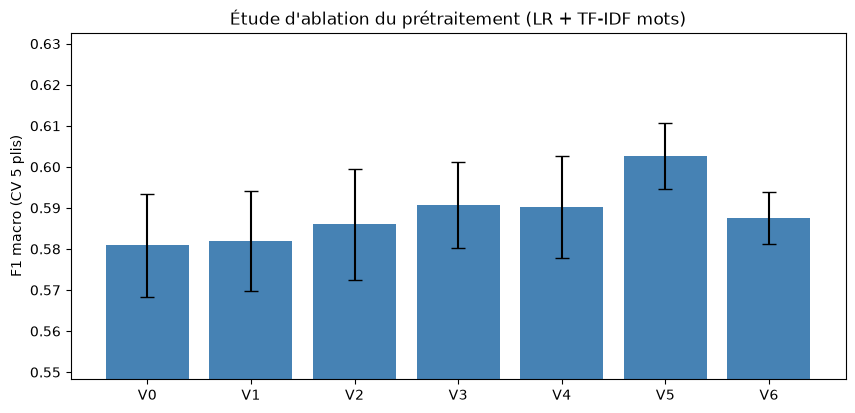

Variante retenue : V5 : V4+lemmes+stop mots perso -> texte_v5
Différence V5 - V6 : +0.0151  (positif = garder les négations aide)


In [20]:
VARIANTES = {
    "V0 : brut": "texte_v0",
    "V1 : HTML+URL+minuscules": "texte_v1",
    "V2 : V1+émojis": "texte_v2",
    "V3 : V2+contractions/argot/allong.": "texte_v3",
    "V4 : V3+négation": "texte_v4",
    "V5 : V4+lemmes+stop mots perso": "texte_v5",
    "V6 : V5, tous stop words": "texte_v6",
}
abl_pipe = Pipeline([("vec", TfidfVectorizer(min_df=3, max_df=0.9, sublinear_tf=True)),
                     ("clf", LogisticRegression(max_iter=2000, random_state=SEED))])
scores_abl = {}
for nom, col in VARIANTES.items():
    scores_abl[nom] = cross_val_score(abl_pipe, train_df[col], train_df["label"], cv=CV5, scoring="f1_macro", n_jobs=-1)

abl = pd.DataFrame({"F1 macro (moyenne)": {k: v.mean() for k, v in scores_abl.items()},
                    "Écart-type": {k: v.std() for k, v in scores_abl.items()}})
abl["Gain vs variante précédente"] = abl["F1 macro (moyenne)"].diff()
abl["Gain > écart-type ?"] = abl["Gain vs variante précédente"].abs() > abl["Écart-type"]
display(abl.round(4))

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(range(len(abl)), abl["F1 macro (moyenne)"], yerr=abl["Écart-type"], capsize=5, color="steelblue")
ax.set_xticks(range(len(abl))); ax.set_xticklabels([k.split(" :")[0] for k in abl.index])
lo = (abl["F1 macro (moyenne)"] - abl["Écart-type"]).min() - 0.02
ax.set_ylim(max(0, lo), abl["F1 macro (moyenne)"].max() + 0.03)
ax.set_ylabel("F1 macro (CV 5 plis)"); ax.set_title("Étude d'ablation du prétraitement (LR + TF-IDF mots)")
plt.show()

# Variante retenue : meilleur F1 macro moyen (modifiable : mets par exemple BEST_VARIANT = "V3 : ...")
BEST_VARIANT = abl["F1 macro (moyenne)"].idxmax()
BEST_COL = VARIANTES[BEST_VARIANT]
print("Variante retenue :", BEST_VARIANT, "->", BEST_COL)
ecart_v5_v6 = abl.loc["V5 : V4+lemmes+stop mots perso", "F1 macro (moyenne)"] - abl.loc["V6 : V5, tous stop words", "F1 macro (moyenne)"]
print(f"Différence V5 - V6 : {ecart_v5_v6:+.4f}  (positif = garder les négations aide)")

In [21]:
# Q4 : l'effet du prétraitement dépend-il de la représentation et du classifieur ? (expérience)
rows = []
for nom in MODELES:
    for kind in ["bow", "tfidf_word"]:
        for vn, col in [("V0", "texte_v0"), ("V3", "texte_v3"), ("V5", "texte_v5")]:
            pipe = Pipeline([("vec", make_vec(kind)), ("clf", nouveau_modele(nom))])
            s = cross_val_score(pipe, train_df[col], train_df["label"], cv=CV5, scoring="f1_macro", n_jobs=-1)
            rows.append({"modèle": nom, "représentation": kind, "variante": vn, "F1": s.mean()})
exp = pd.DataFrame(rows).pivot_table(index=["modèle", "représentation"], columns="variante", values="F1")
exp["gain V5 - V0"] = exp["V5"] - exp["V0"]
display(exp.round(4))

variante                                  V0      V3      V5  gain V5 - V0
modèle                représentation                                      
Naive Bayes           bow             0.5843  0.5921  0.5989        0.0146
                      tfidf_word      0.5042  0.5040  0.5335        0.0294
Regression logistique bow             0.5849  0.5927  0.5969        0.0119
                      tfidf_word      0.5809  0.5907  0.6026        0.0218
SVM lineaire          bow             0.5584  0.5621  0.5684        0.0101
                      tfidf_word      0.5819  0.5907  0.5957        0.0138

**Réponses (Section 6)**

1. La variante qui a le meilleur F1 macro est indiquée par la cellule d'ablation (« Variante retenue »). La colonne « Gain > écart-type ? » indique si l'écart avec la variante précédente dépasse la variabilité de la validation croisée. **Un gain inférieur à l'écart-type n'est pas démontré** : il peut venir du hasard du découpage.
2. Les opérations qui apportent un gain net sont celles dont la ligne du tableau montre un gain supérieur à l'écart-type ; celles dont le gain est proche de zéro ou négatif n'apportent rien ou dégradent. On confronte ces résultats aux hypothèses du tableau de la section 3 : les hypothèses « émojis » et « négation » sont celles qu'il faut surtout regarder, car ce sont celles qui ont du sens pour la polarité. Les résultats mesurés priment sur l'hypothèse.
3. **V5 contre V6** : V6 supprime tous les stop words, y compris `not`, `no`, `never`, les intensifieurs et les connecteurs d'opposition. La différence V5 − V6 (affichée) mesure l'intérêt de conserver ces mots : retirer la négation transforme « not good » en « good » et détruit le marquage `NEG_`.
4. L'effet du prétraitement dépend de la représentation et du classifieur : un TF-IDF de caractères absorbe déjà les fautes et les allongements (le nettoyage lui apporte moins) ; un modèle à bigrammes capture partiellement la négation (`not good` est un bigramme) ; Naïve Bayes et un modèle linéaire n'exploitent pas pareillement les features rares. Expérience (cellule ci-dessus) : croiser **modèle × représentation × variante** et comparer le gain V5 − V0.
5. On retient la variante affichée comme « retenue » : le critère est le **F1 macro moyen en validation croisée**, interprété avec l'écart-type. À gain équivalent (différence inférieure à l'écart-type), on préférerait la variante la plus simple.

## 7. Évaluation détaillée des modèles

On part de la meilleure variante de prétraitement (`BEST_COL`). Si ce n'est pas la variante utilisée en 5.3 (`texte_avance`), les hyperparamètres sont **réoptimisés sur le train** avec cette variante. Puis chaque modèle optimisé est évalué **une seule fois** sur le test.

### 7.1 Rappel des métriques
Pour une classe c (un contre tous) : Précision = TP / (TP + FP), Rappel = TP / (TP + FN), F1 = 2·P·R / (P + R), Accuracy = ΣTP / N. Moyennes : **macro** (moyenne simple des classes), **pondérée** (par l'effectif) et **micro** (comptage global).

In [22]:
if BEST_COL == "texte_avance":
    GRIDS = GRIDS_V5
    print("Hyperparamètres de 5.3 conservés (même variante).")
else:
    print("Réoptimisation sur la variante retenue :", BEST_COL)
    GRIDS = optimiser(BEST_COL, BEST_CW)

def scores_matrix(model, X):
    return model.predict_proba(X) if hasattr(model, "predict_proba") else model.decision_function(X)

def auc_ovr_macro(y, S, classes):
    return np.mean([roc_auc_score((np.asarray(y) == c).astype(int), S[:, i]) for i, c in enumerate(classes)])

# ====== ÉVALUATION FINALE SUR LE TEST (une seule fois) ======
X_test_text, y_test = test_df[BEST_COL], test_df["label"]
FINAL = {}
for nom in MODELES:
    est = clone(GRIDS[nom].best_estimator_)
    t0 = time.time(); est.fit(train_df[BEST_COL], y_train); t_fit = time.time() - t0
    t0 = time.time(); y_pred = est.predict(X_test_text); t_pred = time.time() - t0
    S = scores_matrix(est, X_test_text)
    FINAL[nom] = dict(est=est, y_pred=y_pred, S=S, t_fit=t_fit, t_pred=t_pred,
                      auc=auc_ovr_macro(y_test, S, est.classes_))
print("Évaluation finale terminée (test utilisé une seule fois).")

Réoptimisation sur la variante retenue : texte_v5
Naive Bayes            | meilleurs paramètres : {'clf__alpha': 0.1, 'vec__ngram_range': (1, 2)} | F1 macro CV = 0.5712
Regression logistique  | meilleurs paramètres : {'clf__C': 1, 'vec__ngram_range': (1, 1)} | F1 macro CV = 0.6197
SVM lineaire           | meilleurs paramètres : {'clf__C': 0.1, 'vec__ngram_range': (1, 1)} | F1 macro CV = 0.6244
Évaluation finale terminée (test utilisé une seule fois).


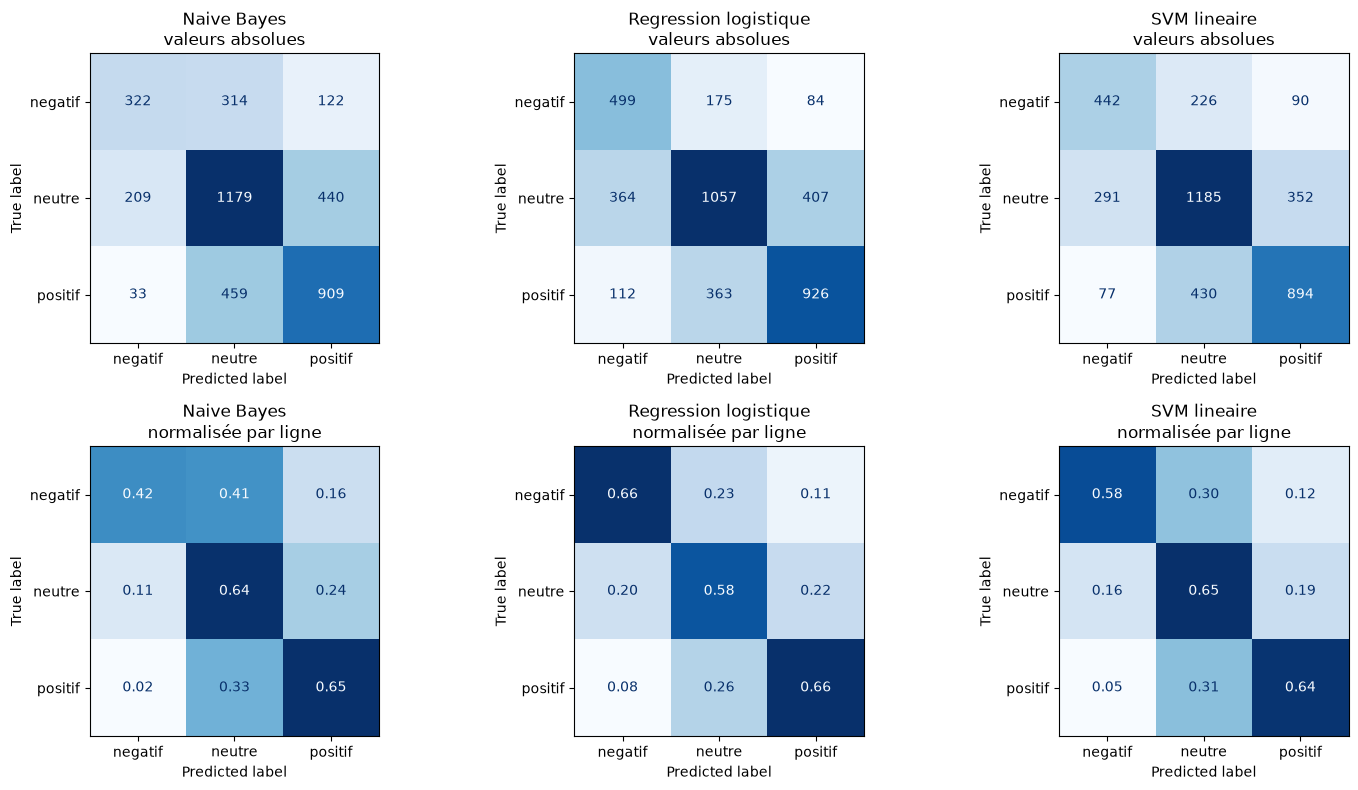

 Naive Bayes 
              precision    recall  f1-score   support

     negatif      0.571     0.425     0.487       758
      neutre      0.604     0.645     0.624      1828
     positif      0.618     0.649     0.633      1401

    accuracy                          0.604      3987
   macro avg      0.598     0.573     0.581      3987
weighted avg      0.603     0.604     0.601      3987

 Regression logistique 
              precision    recall  f1-score   support

     negatif      0.512     0.658     0.576       758
      neutre      0.663     0.578     0.618      1828
     positif      0.653     0.661     0.657      1401

    accuracy                          0.623      3987
   macro avg      0.609     0.632     0.617      3987
weighted avg      0.631     0.623     0.624      3987

 SVM lineaire 
              precision    recall  f1-score   support

     negatif      0.546     0.583     0.564       758
      neutre      0.644     0.648     0.646      1828
     positif      0.66

In [23]:
# 7.2 Matrices de confusion (absolues puis normalisées par ligne) + classification_report
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for j, nom in enumerate(MODELES):
    yp = FINAL[nom]["y_pred"]
    ConfusionMatrixDisplay.from_predictions(y_test, yp, labels=LABELS, ax=axes[0, j], cmap="Blues", colorbar=False)
    axes[0, j].set_title(f"{nom}\nvaleurs absolues")
    ConfusionMatrixDisplay.from_predictions(y_test, yp, labels=LABELS, normalize="true", ax=axes[1, j],
                                            cmap="Blues", colorbar=False, values_format=".2f")
    axes[1, j].set_title(f"{nom}\nnormalisée par ligne")
plt.tight_layout(); plt.show()

for nom in MODELES:
    print("=" * 60, "\n", nom, "\n", "=" * 60)
    print(classification_report(y_test, FINAL[nom]["y_pred"], labels=LABELS, digits=3))

In [24]:
# 7.3 Comparaison statistique : F1 macro en validation croisée répétée (sur le train) + tests appariés
RCV = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=SEED)
cv_scores = {nom: cross_val_score(clone(GRIDS[nom].best_estimator_), train_df[BEST_COL], y_train,
                                  cv=RCV, scoring="f1_macro", n_jobs=-1) for nom in MODELES}
display(pd.DataFrame({"F1 macro (moyenne CV)": {k: v.mean() for k, v in cv_scores.items()},
                      "écart-type": {k: v.std() for k, v in cv_scores.items()}}).round(4))

print("Tests t appariés sur les 10 scores de plis (mêmes découpages) :")
paires = [(MODELES[0], MODELES[1]), (MODELES[0], MODELES[2]), (MODELES[1], MODELES[2])]
for a, b in paires:
    t, p = stats.ttest_rel(cv_scores[a], cv_scores[b])
    print(f"  {a:22s} vs {b:22s} : diff moyenne = {np.mean(cv_scores[a]-cv_scores[b]):+.4f}, p = {p:.4f}")
print("  (les plis ne sont pas indépendants : p-valeurs à interpréter avec prudence)")

print("\nTest de McNemar sur les prédictions du test (erreurs de A vs B) :")
for a, b in paires:
    ok_a = FINAL[a]["y_pred"] == y_test.values; ok_b = FINAL[b]["y_pred"] == y_test.values
    n01 = int(np.sum(ok_a & ~ok_b)); n10 = int(np.sum(~ok_a & ok_b))
    chi2 = (abs(n01 - n10) - 1) ** 2 / max(n01 + n10, 1)
    print(f"  {a:22s} vs {b:22s} : A seul correct = {n01}, B seul correct = {n10}, p = {1 - stats.chi2.cdf(chi2, 1):.4f}")

,F1 macro (moyenne CV),écart-type
Naive Bayes,0.5713,0.0090
Regression logistique,0.6200,0.0065
SVM lineaire,0.6234,0.0080


Tests t appariés sur les 10 scores de plis (mêmes découpages) :
  Naive Bayes            vs Regression logistique  : diff moyenne = -0.0487, p = 0.0000
  Naive Bayes            vs SVM lineaire           : diff moyenne = -0.0521, p = 0.0000
  Regression logistique  vs SVM lineaire           : diff moyenne = -0.0034, p = 0.1428
  (les plis ne sont pas indépendants : p-valeurs à interpréter avec prudence)

Test de McNemar sur les prédictions du test (erreurs de A vs B) :
  Naive Bayes            vs Regression logistique  : A seul correct = 432, B seul correct = 504, p = 0.0203
  Naive Bayes            vs SVM lineaire           : A seul correct = 382, B seul correct = 493, p = 0.0002
  Regression logistique  vs SVM lineaire           : A seul correct = 112, B seul correct = 151, p = 0.0191


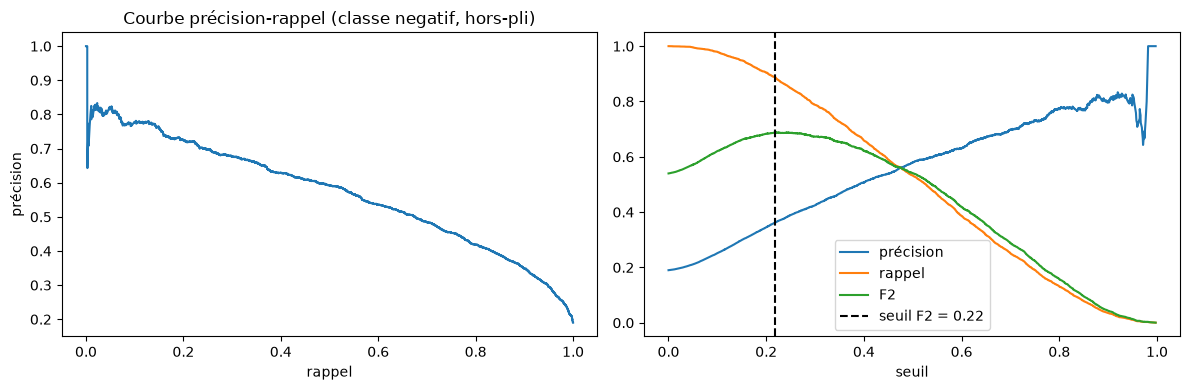

Seuil qui maximise le F2 (rappel favorisé) : 0.22 (seuil par défaut : argmax des probabilités)


In [25]:
# Réflexion : choix du seuil de la classe « negatif » (sélection sur prédictions hors-pli du TRAIN, pas sur le test)
lr_best = clone(GRIDS["Regression logistique"].best_estimator_)
proba_oof = cross_val_predict(lr_best, train_df[BEST_COL], y_train, cv=CV5, method="predict_proba", n_jobs=-1)
i_neg = list(lr_best.fit(train_df[BEST_COL], y_train).classes_).index("negatif")
y_neg = (y_train.values == "negatif").astype(int)
prec, rec, thr = precision_recall_curve(y_neg, proba_oof[:, i_neg])
f2 = (5 * prec[:-1] * rec[:-1]) / np.maximum(4 * prec[:-1] + rec[:-1], 1e-9)   # F2 : le rappel pèse plus que la précision
seuil = thr[np.argmax(f2)]

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(rec, prec); ax[0].set_xlabel("rappel"); ax[0].set_ylabel("précision"); ax[0].set_title("Courbe précision-rappel (classe negatif, hors-pli)")
ax[1].plot(thr, prec[:-1], label="précision"); ax[1].plot(thr, rec[:-1], label="rappel"); ax[1].plot(thr, f2, label="F2")
ax[1].axvline(seuil, color="k", ls="--", label=f"seuil F2 = {seuil:.2f}"); ax[1].set_xlabel("seuil"); ax[1].legend()
plt.tight_layout(); plt.show()
print(f"Seuil qui maximise le F2 (rappel favorisé) : {seuil:.2f} (seuil par défaut : argmax des probabilités)")

**Réponses (Section 7)**

1. **Structure de la matrice de confusion (3 classes)** : matrice 3 × 3. Les **lignes** sont les classes réelles, les **colonnes** les classes prédites, la **diagonale** contient les bien classés. Hors diagonale : les erreurs, par exemple la case (négatif, neutre) compte les tweets négatifs prédits neutres. Normalisée par ligne, la diagonale est le **rappel** de chaque classe.
2. La paire la plus souvent confondue est affichée dans la cellule d'analyse ci-dessous (calculée automatiquement). En général, ce sont des confusions impliquant **neutre** (neutre ↔ positif ou neutre ↔ négatif), et elles ont tendance à être similaires pour les trois modèles puisque le problème vient des données (frontières floues).
3. **Précision vs rappel pour « négatif »** : la précision répond à « parmi les tweets prédits négatifs, combien le sont vraiment ? » ; le rappel à « parmi les vrais tweets négatifs, combien ai-je retrouvés ? ». Pour une veille de satisfaction client, on privilégie le **rappel de la classe négatif** : manquer un client mécontent coûte plus cher qu'une fausse alerte (qu'on filtre ensuite).
4. L'accuracy est trompeuse quand les classes sont **déséquilibrées** : une classe majoritaire à 45 % ou plus permet d'avoir une accuracy correcte en ignorant les classes rares. Notre jeu présente ce risque (voir section 2 : accuracy du classifieur majoritaire), d'où l'usage du F1 macro et du rappel par classe.

**Question de réflexion (rappel des clients mécontents)** : on choisit le seuil de décision de la classe « négatif » en fonction du **coût relatif** des erreurs : un faux négatif (client non détecté) coûte plus qu'un faux positif (rappel inutile). On abaisse donc le seuil pour augmenter le rappel, au prix de la précision, par exemple en maximisant un F-bêta avec β > 1 (F2 ci-dessus), ou en minimisant un coût attendu. La **courbe précision-rappel** (et la courbe ROC) aide à choisir ce seuil ; la sélection doit se faire sur des prédictions de validation (ici hors-pli sur le train), jamais sur le test.

## 8. Comparaison détaillée des trois classifieurs

### 8.1 Tableau comparatif global (test, modèles optimisés, moyennes macro)

In [26]:
rows = []
for nom in MODELES:
    yp = FINAL[nom]["y_pred"]
    p, r, f, _ = precision_recall_fscore_support(y_test, yp, average="macro", zero_division=0)
    rows.append({"Modèle": nom, "Acc.": accuracy_score(y_test, yp), "Préc.": p, "Rappel": r, "F1": f,
                 "AUC": FINAL[nom]["auc"], "Entr. (s)": FINAL[nom]["t_fit"], "Préd. (s)": FINAL[nom]["t_pred"]})
tab81 = pd.DataFrame(rows).set_index("Modèle")
display(tab81.round(4))
MEILLEUR = tab81["F1"].idxmax()
print("Meilleur modèle (F1 macro sur le test) :", MEILLEUR)

# 8.2 Tableau par classe
rows = []
for nom in MODELES:
    p, r, f, _ = precision_recall_fscore_support(y_test, FINAL[nom]["y_pred"], labels=LABELS, zero_division=0)
    for i, c in enumerate(LABELS):
        rows.append({"Modèle": nom, "Classe": c, "Précision": p[i], "Rappel": r[i], "F1": f[i]})
tab82 = pd.DataFrame(rows)
display(tab82.round(4))

,Acc.,Préc.,Rappel,F1,AUC,Entr. (s),Préd. (s)
Modèle,,,,,,,
Naive Bayes,0.6045,0.5976,0.5729,0.5813,0.7824,1.5048,0.1470
Regression logistique,0.6225,0.6093,0.6325,0.6169,0.8127,2.0406,0.0805
SVM lineaire,0.6323,0.6195,0.6232,0.6210,0.8111,0.6466,0.1010


Meilleur modèle (F1 macro sur le test) : SVM lineaire


,Modèle,Classe,Précision,Rappel,F1
0,Naive Bayes,negatif,0.5709,0.4248,0.4871
1,Naive Bayes,neutre,0.6040,0.6450,0.6238
2,Naive Bayes,positif,0.6179,0.6488,0.6330
3,Regression logistique,negatif,0.5118,0.6583,0.5759
4,Regression logistique,neutre,0.6627,0.5782,0.6176
5,Regression logistique,positif,0.6535,0.6610,0.6572
6,SVM lineaire,negatif,0.5457,0.5831,0.5638
7,SVM lineaire,neutre,0.6437,0.6482,0.6460
8,SVM lineaire,positif,0.6692,0.6381,0.6533


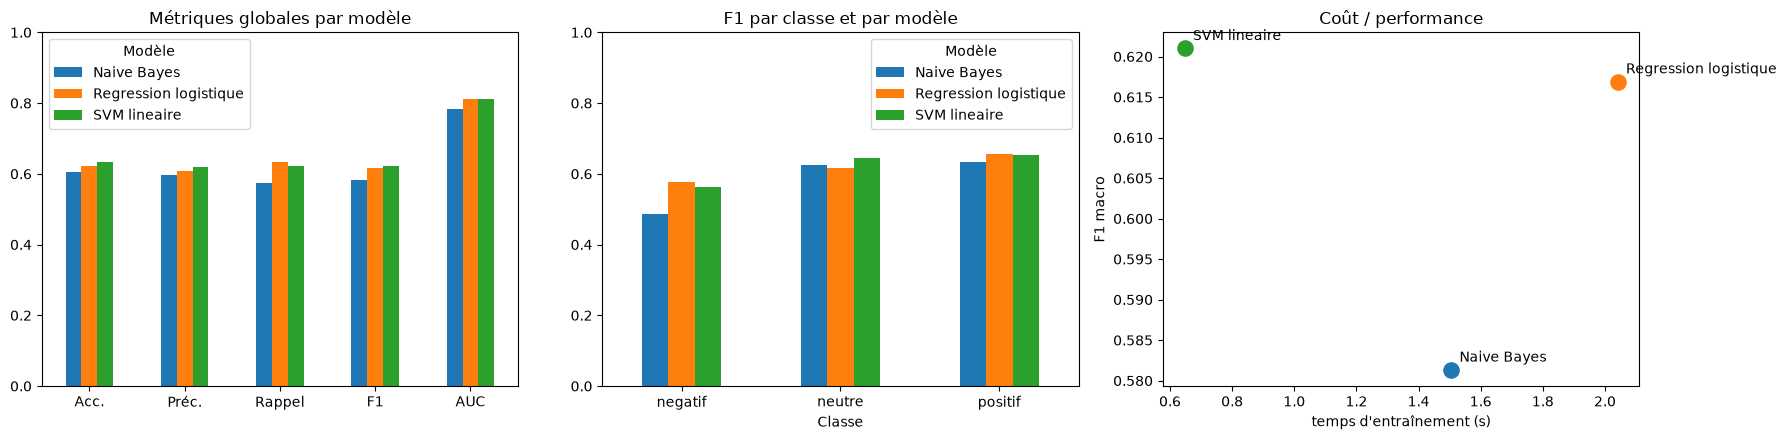

In [27]:
# 8.3 Visualisations
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
# (i) barres groupées des métriques par modèle
tab81[["Acc.", "Préc.", "Rappel", "F1", "AUC"]].T.plot(kind="bar", ax=axes[0], rot=0)
axes[0].set_title("Métriques globales par modèle"); axes[0].set_ylim(0, 1)
# (ii) F1 par classe et par modèle
tab82.pivot(index="Classe", columns="Modèle", values="F1").reindex(LABELS).plot(kind="bar", ax=axes[1], rot=0)
axes[1].set_title("F1 par classe et par modèle"); axes[1].set_ylim(0, 1)
# (iii) temps d'entraînement vs F1
for nom in MODELES:
    axes[2].scatter(tab81.loc[nom, "Entr. (s)"], tab81.loc[nom, "F1"], s=120)
    axes[2].annotate(nom, (tab81.loc[nom, "Entr. (s)"], tab81.loc[nom, "F1"]), textcoords="offset points", xytext=(6, 6))
axes[2].set_xlabel("temps d'entraînement (s)"); axes[2].set_ylabel("F1 macro"); axes[2].set_title("Coût / performance")
plt.tight_layout(); plt.show()

### 8.4 Analyse des erreurs du meilleur modèle
La typologie ci-dessous est une **première classification automatique par règles** (lexique simple, confiance du modèle, longueur, vocabulaire inconnu). Elle sert de base : relis les 15 exemples affichés et corrige à la main les types qui te semblent faux avant de rendre.

SVM lineaire : 1466 erreurs sur 3987 textes de test


erreurs
label   pred            
positif neutre       430
neutre  positif      352
        negatif      291
negatif neutre       226
        positif       90
positif negatif       77


Confusion la plus fréquente : réel = positif -> prédit = neutre
Rappel : cette paire est calculée pour le meilleur modèle ; les matrices de la section 7 montrent les trois modèles.
  Naive Bayes            : paire la plus confondue = positif -> neutre (459 cas)
  Regression logistique  : paire la plus confondue = neutre -> positif (407 cas)
  SVM lineaire           : paire la plus confondue = positif -> neutre (430 cas)


,texte,label,pred,type d'erreur
3194,"""Tomorrow's the night! Weekly lesbian discussion group at Gay's the Word, WC1N, 8-9pm, every Wednesday @user",positif,neutre,autre
3262,@user follow @user \u002c find her on NOVEMBER 26. meet her. she\u2019ll be at the bell center by 4:00pm I...,positif,neutre,autre
611,If I didnt have you I'd never see the sun. #MTVStars Lady Gaga,positif,neutre,autre
1807,"@user I'm actually probably gunna buy it. (Danny Elfman enthusiast, can't help myself!), but i'll let you ...",positif,neutre,autre
3187,"""We get to keep Curtis, right? He's going to be a regular? He's going to be in the Arrow Cave soon?",positif,neutre,autre
777,"""We will miss you Frank Gifford, NFL Legend &amp; hubby of @user Now walking in Glory &amp; Wonder with Go...",positif,neutre,autre
2826,"""We have four Premium Seats for the Zac Brown Band, for this Friday Night 8/7/15 at Fenway Park. These ar...",positif,neutre,autre
1822,Grateful Dead Ship of the Sun Poster Original Numbered Edition A Kelley H Greene,positif,neutre,autre
673,Philly!!! @user will be rocking A FREE SHOW @ the Liacouras center @ 7pm THIS FRIDAY! Come through and wat...,neutre,positif,erreur d'annotation probable
135,"""But I'll just read """"Paper Towns"""" while I wait because I'm seeing it tomorrow.""",neutre,positif,autre


,% des erreurs de l'échantillon
type d'erreur,
autre,93.3
erreur d'annotation probable,3.3
vocabulaire inconnu,1.7
sentiments mixtes,1.7


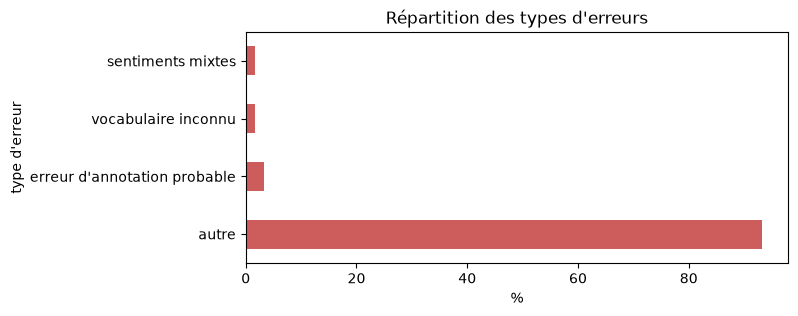

In [ ]:
best_pred = FINAL[MEILLEUR]["y_pred"]
S_best = FINAL[MEILLEUR]["S"]
err = test_df.copy()
err["pred"] = best_pred
if S_best.shape[1] == 3:
    srt = np.sort(S_best, axis=1)
    err["conf"] = srt[:, -1] if hasattr(FINAL[MEILLEUR]["est"], "predict_proba") else (srt[:, -1] - srt[:, -2])
err = err[err["label"] != err["pred"]].copy()
print(f"{MEILLEUR} : {len(err)} erreurs sur {len(test_df)} textes de test")

paires_err = err.groupby(["label", "pred"]).size().sort_values(ascending=False)
display(paires_err.rename("erreurs").to_frame())
(par_a, par_b) = paires_err.index[0]
print(f"\nConfusion la plus fréquente : réel = {par_a} -> prédit = {par_b}")
print("Rappel : cette paire est calculée pour le meilleur modèle ; les matrices de la section 7 montrent les trois modèles.")
for nom in MODELES:
    cm = confusion_matrix(y_test, FINAL[nom]["y_pred"], labels=LABELS).copy()
    np.fill_diagonal(cm, 0)
    i, j = np.unravel_index(cm.argmax(), cm.shape)
    print(f"  {nom:22s} : paire la plus confondue = {LABELS[i]} -> {LABELS[j]} ({cm[i, j]} cas)")

# ---- Typologie automatique ----
POS_W = set("good great love loved best amazing awesome happy excellent perfect nice wonderful beautiful thanks thank fantastic enjoy fun win won".split())
NEG_W = set("bad worst hate hated terrible awful horrible sad angry disappointed poor delayed late lost broke rude sucks stupid worse annoying cancelled fail".split())
vocab_train = set(w for t in train_df[BEST_COL] for w in t.split())

def typer_erreur(r):
    toks = r[BEST_COL].split()
    low = [w.replace("neg_", "") for w in toks]
    has_neg = any(w.startswith("neg_") for w in toks) or bool(re.search(r"\b(not|never|no|cannot)\b|n't", r["texte"], re.I))
    has_pos, has_negw = any(w in POS_W for w in low), any(w in NEG_W for w in low)
    oov = np.mean([w not in vocab_train for w in toks]) if toks else 0
    n_utiles = len([w for w in r["texte"].split() if not w.startswith(("@", "http"))])
    conf = r.get("conf", np.nan)
    seuil_conf = 0.9 if hasattr(FINAL[MEILLEUR]["est"], "predict_proba") else 1.0
    if has_neg and (has_pos or has_negw):                     return "négation mal gérée"
    if r["label"] == "negatif" and r["pred"] == "positif" and has_pos: return "ironie ou sarcasme"
    if has_pos and has_negw:                                  return "sentiments mixtes"
    if oov > 0.4:                                             return "vocabulaire inconnu"
    if n_utiles <= 5:                                         return "texte ambigu ou sans contexte"
    if conf == conf and conf >= seuil_conf:                   return "erreur d'annotation probable"
    return "autre"

n_ech = min(60, len(err))
ech = err.sample(n_ech, random_state=SEED).copy()
ech["type d'erreur"] = ech.apply(typer_erreur, axis=1)

# 15+ erreurs en ciblant les confusions les plus fréquentes
cibles = []
for (a, b) in paires_err.index[:2]:
    cibles.append(ech[(ech.label == a) & (ech.pred == b)].head(8))
affiche = pd.concat(cibles)
if len(affiche) < 15:
    affiche = pd.concat([affiche, ech.drop(affiche.index).head(15 - len(affiche))])
display(affiche[["texte", "label", "pred", "type d'erreur"]].head(max(15, len(affiche))))

rep = (100 * ech["type d'erreur"].value_counts(normalize=True)).round(1)
display(rep.rename("% des erreurs de l'échantillon").to_frame())
rep.plot(kind="barh", figsize=(7, 3), color="indianred"); plt.xlabel("%"); plt.title("Répartition des types d'erreurs"); plt.show()

### 8.5 Interprétation des modèles : termes les plus discriminants

In [ ]:
def top_terms(est, k=15):
    vec, clf = est.named_steps["vec"], est.named_steps["clf"]
    names = np.array(vec.get_feature_names_out())
    if hasattr(clf, "coef_"):
        W = clf.coef_
    else:                                                    # Naïve Bayes : log P(w|c) - moyenne sur les classes
        lp = clf.feature_log_prob_
        W = lp - lp.mean(axis=0, keepdims=True)
    return {c: list(names[np.argsort(W[i])[::-1][:k]]) for i, c in enumerate(clf.classes_)}

EMOJI_WORDS = {"smile", "laugh", "wink", "cry", "sad", "tongue", "love", "skeptical", "surprise"}
for nom in MODELES:
    tt = top_terms(FINAL[nom]["est"])
    print("=" * 70, "\n", nom, "\n", "=" * 70)
    display(pd.DataFrame(tt))
    tous = [t for c in tt for t in tt[c]]
    n_neg = sum(t.startswith("neg_") for t in tous)
    n_spec = sum(t in {s.lower() for s in SPECIAL} for t in tous)
    n_emo = sum((t in EMOJI_WORDS) or ("face" in t) or ("heart" in t) for t in tous)
    print(f"Dans ces 45 termes : jetons NEG_ = {n_neg}, jetons spéciaux (URL, USER, EXCL, ALLCAPS...) = {n_spec}, émojis/émoticônes convertis = {n_emo}\n")

 Naive Bayes 


,negatif,neutre,positif
0,alt rightist,gucci bag,so excited
1,jew,nowplaye,excellent
2,neo,thine,congrat
3,pathetic,david de,good day
4,manslaughter charge,correct,excited
5,puppet,midfielder,red_heart
6,deport,situation,happiness
7,ridiculous,aldean ticket,amazing
8,neo nazi,evidence,happy sunday
9,leftist,play thursday,smiling_face_with_heart


Dans ces 45 termes : jetons NEG_ = 1, jetons spéciaux (URL, USER, EXCL, ALLCAPS...) = 0, émojis/émoticônes convertis = 3

 Regression logistique 


,negatif,neutre,positif
0,fuck,kane,good
1,bad,gucci,love
2,not,registration,happy
3,sad,different,great
4,shit,abc,neg_wait
5,lose,cub,excited
6,wrong,libya,thank
7,kill,trend,smile
8,idiot,preview,fun
9,hate,left,awesome


Dans ces 45 termes : jetons NEG_ = 1, jetons spéciaux (URL, USER, EXCL, ALLCAPS...) = 1, émojis/émoticônes convertis = 3

 SVM lineaire 


,negatif,neutre,positif
0,fuck,kane,good
1,bad,gucci,love
2,not,registration,happy
3,shit,sox,excited
4,sad,preview,great
5,lose,oct,neg_wait
6,kill,trend,smile
7,wrong,cub,thank
8,idiot,different,fun
9,nazi,abc,enjoy


Dans ces 45 termes : jetons NEG_ = 1, jetons spéciaux (URL, USER, EXCL, ALLCAPS...) = 1, émojis/émoticônes convertis = 3



**Réponses (Section 8)**

1. Le meilleur modèle global est celui qui a le plus haut F1 macro (affiché dans la cellule « Meilleur modèle »). L'écart doit être comparé à l'écart-type de la validation croisée et aux tests de la section 7.3 : si la différence est plus petite que l'écart-type et que la p-valeur n'est pas faible, on **ne peut pas** conclure qu'un modèle est meilleur.
2. Le meilleur modèle pour la classe « négatif » et pour « neutre » se lit dans le tableau 8.2 (colonne F1, ou rappel selon l'objectif). Le classement n'est pas forcément le même selon les classes : par exemple, Naïve Bayes peut avoir un meilleur rappel sur une classe fréquente mais une précision plus faible.
3. **Performance et coût** : Naïve Bayes est le plus rapide (un simple comptage), le SVM linéaire est très rapide aussi, la régression logistique est en général plus lente (optimisation itérative) mais donne des probabilités. Pour un système temps réel traitant des millions de tweets, on privilégie un modèle **linéaire** (SVM ou LR) à l'inférence peu coûteuse (produit scalaire avec une matrice creuse) ; le choix final dépend du tableau 8.1 (F1 vs temps).
4. Types d'erreurs dominants : voir la répartition ci-dessus. Peuvent être corrigés par un meilleur prétraitement : négation mal gérée, vocabulaire inconnu (normalisation, caractères n-grammes), émojis. Nécessitent un modèle plus puissant : ironie et sarcasme, sentiments mixtes, contexte manquant, ambiguïtés. Les erreurs d'annotation ne se corrigent que par de meilleures données.
5. Cohérence des termes : on doit retrouver des mots d'opinion (good, love, bad, hate), des jetons `NEG_`, `EXCL`, des émojis convertis. Un **risque de mauvaise généralisation** apparaît si des termes discriminants sont des noms propres, des noms de produits ou de compagnies, des jetons techniques (`URL`, `USER`) ou des artefacts de collecte : le modèle apprendrait des indices artificiels du jeu de données plutôt que le sentiment.
6. **Naïve Bayes reste compétitif** quand les données sont peu nombreuses (peu de paramètres à estimer), quand la rapidité compte, comme **baseline** simple, ou pour des vecteurs très creux avec peu de features corrélées.
7. **Limites du sac de mots + modèle linéaire** : l'ordre des mots est perdu (seuls les n-grammes en gardent un peu), pas de compréhension de l'ironie ni du contexte, polysémie (un même mot a un seul poids). Un **Transformer** (BERT, RoBERTa, XLM-R) apporte des représentations **contextuelles** : le même mot a un vecteur différent selon la phrase, l'attention capte les dépendances longues (négation lointaine) et le pré-entraînement réduit le besoin de données annotées.

## Questions de synthèse et de compréhension

1. **Chaîne complète** : collecte (Hugging Face / Kaggle) → échantillon stratifié de 20 000 textes → exploration (classes, longueurs, bruit) → nettoyage modulaire (structurel, URL/mentions, hashtags, émojis, contractions/argot, allongements, MAJUSCULES, négation, lemmatisation + stop words personnalisés) → suppression des textes trop courts et des doublons → découpage 80/20 stratifié → vectorisation dans un `Pipeline` (BoW, TF-IDF mots, TF-IDF caractères) → entraînement de NB, LR et SVM → gestion du déséquilibre (`class_weight`) → optimisation par `GridSearchCV` → ablation du prétraitement par validation croisée → choix de la variante → évaluation finale unique sur le test (matrices de confusion, rapports, comparaison) → analyse des erreurs et des termes discriminants.
2. **Nettoyage spécifique à l'analyse de sentiments** (par rapport à une classification thématique) : conversion des émojis en texte, **conservation des négations** (ne pas les traiter comme stop words), marquage de la portée de la négation, intensifieurs et connecteurs d'opposition gardés, indicateurs d'allongement (`ELONG`), de ponctuation expressive (`EXCL`) et de MAJUSCULES (`ALLCAPS`). Pour une classification thématique, ces éléments sont du bruit ; ici ils portent le sentiment. La justification chiffrée est dans le tableau d'ablation (gain V3/V4/V5 et comparaison V5 vs V6).
3. **Isoler le test et ajuster tout sur le train** : le test simule des données jamais vues. Si le vectoriseur (vocabulaire, IDF) ou les hyperparamètres sont choisis en regardant le test, l'information du test fuit dans le modèle (*leakage*), le score est optimiste et ne reflète plus la performance en production. Utiliser le test plusieurs fois revient aussi à l'utiliser pour choisir, donc à surapprendre sur lui.
4. **Métriques** : *accuracy* = part des prédictions correctes (trompeuse si classes déséquilibrées) ; *précision* = fiabilité des prédictions d'une classe ; *rappel* = part des vrais exemples d'une classe retrouvés ; *F1* = moyenne harmonique précision/rappel. **Macro** : moyenne simple des classes (traite toutes les classes de la même façon, adaptée quand les classes rares comptent) ; **pondérée** : moyenne pondérée par l'effectif (reflète la distribution réelle) ; **micro** : comptage global (en classification multi-classe mono-label, le F1 micro est égal à l'accuracy).
5. **Comparaison des modèles** : *NB* : génératif, hypothèse d'indépendance des mots, très rapide, très bon avec peu de données, mais probabilités mal calibrées. *LR* : discriminatif, probabilités, régularisation L2, un peu plus coûteuse. *SVM linéaire* : marge maximale, souvent la meilleure sur du texte creux, rapide, mais pas de probabilités directes. Coût : NB < SVM ≲ LR à l'entraînement ; tous les trois sont très rapides à l'inférence.
6. **Précautions pour une comparaison équitable** : mêmes découpages (même `random_state`, mêmes plis), mêmes métriques, mêmes données prétraitées, hyperparamètres optimisés avec le même budget et uniquement sur le train, test utilisé une seule fois, écarts interprétés au regard de l'écart-type et de tests statistiques, moyennes sur plusieurs répétitions.
7. **Contexte marocain (français, arabe, darija, anglais, parfois en caractères latins)** : *Problèmes* : mélange de langues dans une même phrase (*code-switching*), orthographe non standardisée de la darija en lettres latines (« 3lach », « mzyan »), chiffres utilisés comme lettres, lemmatiseur spaCy et listes de stop words anglais inadaptés, vocabulaire inconnu (OOV), absence de lexiques et de données annotées. *Solutions* : **n-grammes de caractères** (robustes à l'orthographe variable), **modèles multilingues** (XLM-R, mBERT) ou spécialisés (DarijaBERT), **données annotées spécifiques** au contexte marocain, détection de langue par segment, normalisation de la translittération.
8. **Limites éthiques et pratiques** : *vie privée* (tweets publics mais personnels : anonymiser, respecter les CGU et le RGPD), *biais* (le modèle reproduit les biais des annotateurs, surreprésente certains dialectes ou groupes ; un dialecte peut être classé plus « négatif »), *annotation* (annotation automatique via émoticônes ou subjectivité humaine : labels bruités), *usage des résultats* (décisions automatiques sur des personnes, surveillance, manipulation d'opinion) et *représentativité* (les utilisateurs de Twitter ne représentent pas la population), *décalage de domaine*.

---
**Fin du notebook.** Pour rendre le TP : `Kernel > Restart & Run All`, vérifier que toutes les cellules s'exécutent, relire la typologie d'erreurs (8.4), puis envoyer le `.ipynb` via le formulaire indiqué dans l'énoncé.